<a href="https://colab.research.google.com/github/peigemitchell-svg/Google-Colab/blob/main/Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Upload the Wine dataset and import sklear libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#upload "Wine1 dataset" from files located on this computer and sklearn libraries
from google.colab import files
uploaded = files.upload()

#Import sklearn librarie
from sklearn.model_selection import (train_test_split, cross_val_score, GridSearchCV, StratifiedGroupKFold)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)


Saving Wine1.csv to Wine1 (1).csv


In [ ]:
Wine_df = pd.read_csv('Wine1.csv')

#Verify successful loading
print('Dataset loaded successfully.')
print('Dataset shape:', Wine_df.shape)
Wine_df.head()

Dataset loaded successfully.
Dataset shape: (177, 14)


,1,14.23,1.71,2.43,15.6,127,2.8,3.06,0.28,2.29,5.64,1.04,3.92,1065
0,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
2,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
3,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
4,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450


In [ ]:
#Identify missing values
from pandas._libs import missing
missing_values = Wine_df.isnull().sum()
print(missing_values)

#Replace missing values with 'Unknown'
missing_values = Wine_df.fillna('Unknown', inplace=True)
print(missing_values)

1        0
14.23    0
1.71     0
2.43     0
15.6     0
127      0
2.8      0
3.06     0
0.28     0
2.29     0
5.64     0
1.04     0
3.92     0
1065     0
dtype: int64
None


In [ ]:
#Add Colum Names
column_names = ['Alcohol', 'Class', 'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Wine_df.columns = column_names

#Verify successful loading
print('Dataset loaded successfully.')
print('Dataset shape:', Wine_df.shape)
Wine_df.head()

Dataset loaded successfully.
Dataset shape: (177, 14)


,Alcohol,Class,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
1,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
2,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
3,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
4,1,14.20,1.76,2.45,15.2,112,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450


In [ ]:
#Recheck the dataset information
print("Dataset Information:")
print(Wine_df.info())

print("\nMissing Values:")
print(Wine_df.isnull().sum())

print("Class Distribution:")
print(Wine_df['Class'].value_counts())

print("\nData Types:")
print(Wine_df.dtypes)

print("Duplicate Rows:")
print(Wine_df.duplicated().sum())

#Recheck the dataset statistics
print("\nSummary Statistics:")
print(Wine_df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 177 entries, 0 to 176
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               177 non-null    int64  
 1   Class                 177 non-null    float64
 2   fixed acidity         177 non-null    float64
 3   volatile acidity      177 non-null    float64
 4   citric acid           177 non-null    float64
 5   residual sugar        177 non-null    int64  
 6   chlorides             177 non-null    float64
 7   free sulfur dioxide   177 non-null    float64
 8   total sulfur dioxide  177 non-null    float64
 9   density               177 non-null    float64
 10  pH                    177 non-null    float64
 11  sulphates             177 non-null    float64
 12  alcohol               177 non-null    float64
 13  quality               177 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.5 KB
None



In [ ]:
#Show the count of each unique value present in within 'Class' target variable.


x = Wine_df.drop('Class', axis=1)
y = Wine_df['Class']

print(x.shape)
print(y.shape)

print('\nTarget Distribution:')
print(y.value_counts().sort_index())

(177, 13)
(177,)

Target Distribution:
Class
11.03    1
11.41    1
11.45    1
11.46    1
11.56    1
        ..
14.37    1
14.38    2
14.39    1
14.75    1
14.83    1
Name: count, Length: 125, dtype: int64


### **Train_Test_Split**

(132, 13)
(45, 13)
(132,)
(45,)


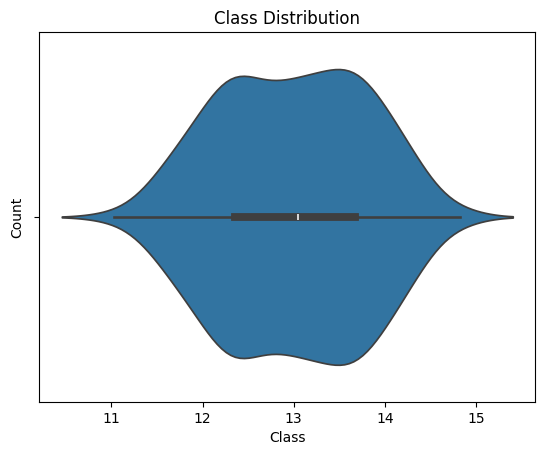

In [ ]:
#Adding the Training and testing with a 75/25 split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

#Verify
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

#add a bar chart with x, y axis
sns.violinplot (x='Class', data=Wine_df)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [29]:
#Provide a summary chart based on each class
Wine_df.groupby('Class').describe()

Alcohol                                    fixed acidity        ...  \
        count mean  std  min  25%  50%  75%  max         count  mean  ...   
Class                                                                 ...   
11.03     1.0  2.0  NaN  2.0  2.0  2.0  2.0  2.0           1.0  1.51  ...   
11.41     1.0  2.0  NaN  2.0  2.0  2.0  2.0  2.0           1.0  0.74  ...   
11.45     1.0  2.0  NaN  2.0  2.0  2.0  2.0  2.0           1.0  2.40  ...   
11.46     1.0  2.0  NaN  2.0  2.0  2.0  2.0  2.0           1.0  3.74  ...   
11.56     1.0  2.0  NaN  2.0  2.0  2.0  2.0  2.0           1.0  2.05  ...   
...       ...  ...  ...  ...  ...  ...  ...  ...           ...   ...  ...   
14.37     1.0  1.0  NaN  1.0  1.0  1.0  1.0  1.0           1.0  1.95  ...   
14.38     2.0  1.0  0.0  1.0  1.0  1.0  1.0  1.0           2.0  2.73  ...   
14.39     1.0  1.0  NaN  1.0  1.0  1.0  1.0  1.0           1.0  1.87  ...   
14.75     1.0  1.0  NaN  1.0  1.0  1.0  1.0  1.0           1.0  1.73  ...   
14.83     1.0  1.0  NaN  1.0  1.0  1.0  1.0  1.0           1.0  1.64  ...   

      alcohol       quality                                              \
          75%   max   count    mean         std     min     25%     50%   
Class                                                                     
11.03    2.87  2.87     1.0   407.0         NaN   407.0   407.0   407.0   
11.41    2.31  2.31     1.0   434.0         NaN   434.0   434.0   434.0   
11.45    3.39  3.39     1.0   625.0         NaN   625.0   625.0   625.0   
11.46    2.81  2.81     1.0   562.0         NaN   562.0   562.0   562.0   
11.56    3.69  3.69     1.0   465.0         NaN   465.0   465.0   465.0   
...       ...   ...     ...     ...         ...     ...     ...     ...   
14.37    3.45  3.45     1.0  1480.0         NaN  1480.0  1480.0  1480.0   
14.38    3.33  3.44     2.0  1306.0  340.825469  1065.0  1185.5  1306.0   
14.39    3.58  3.58     1.0  1290.0         NaN  1290.0  1290.0  1290.0   
14.75    2.73  2.73     1.0  1150.0         NaN  1150.0  1150.0  1150.0   
14.83    2.85  2.85     1.0  1045.0         NaN  1045.0  1045.0  1045.0   

                       
          75%     max  
Class                  
11.03   407.0   407.0  
11.41   434.0   434.0  
11.45   625.0   625.0  
11.46   562.0   562.0  
11.56   465.0   465.0  
...       ...     ...  
14.37  1480.0  1480.0  
14.38  1426.5  1547.0  
14.39  1290.0  1290.0  
14.75  1150.0  1150.0  
14.83  1045.0  1045.0  

[125 rows x 104 columns]

       count  mean  std  min  25%  50%  75%  max
Class                                           
11.03    1.0   2.0  NaN  2.0  2.0  2.0  2.0  2.0
11.41    1.0   2.0  NaN  2.0  2.0  2.0  2.0  2.0
11.45    1.0   2.0  NaN  2.0  2.0  2.0  2.0  2.0
11.46    1.0   2.0  NaN  2.0  2.0  2.0  2.0  2.0
11.56    1.0   2.0  NaN  2.0  2.0  2.0  2.0  2.0
...      ...   ...  ...  ...  ...  ...  ...  ...
14.37    1.0   1.0  NaN  1.0  1.0  1.0  1.0  1.0
14.38    2.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
14.39    1.0   1.0  NaN  1.0  1.0  1.0  1.0  1.0
14.75    1.0   1.0  NaN  1.0  1.0  1.0  1.0  1.0
14.83    1.0   1.0  NaN  1.0  1.0  1.0  1.0  1.0

[125 rows x 8 columns]


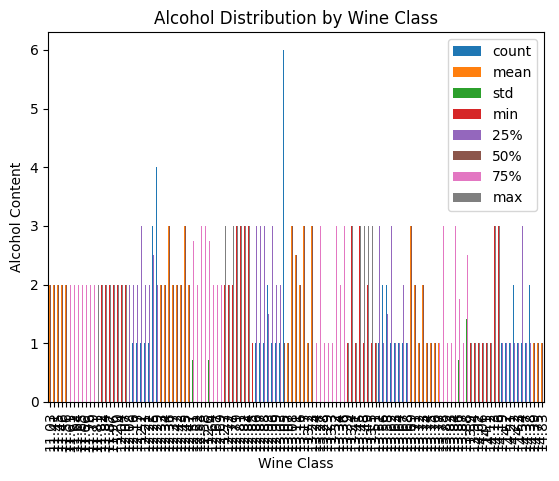

In [30]:
# Summary Statistics for Alcohol by Wine Class
alcohol_stats = Wine_df.groupby('Class')['Alcohol'].describe()
print(alcohol_stats)

#create a bar chart
alcohol_stats.plot(kind='bar')
plt.title('Alcohol Distribution by Wine Class')
plt.xlabel('Wine Class')
plt.ylabel('Alcohol Content')
plt.show()



In [33]:
#Summarize the bar chart by the first 10 rows
alcohol_stats.head(10)




,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
11.03,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.41,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.45,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.46,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.56,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.61,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.62,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.64,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0
11.65,1.0,2.0,NaN,2.0,2.0,2.0,2.0,2.0


In [34]:
print(alcohol_stats['50%'])

Class
11.03    2.0
11.41    2.0
11.45    2.0
11.46    2.0
11.56    2.0
        ... 
14.37    1.0
14.38    1.0
14.39    1.0
14.75    1.0
14.83    1.0
Name: 50%, Length: 125, dtype: float64


/tmp/ipykernel_3047/3754642249.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Alcohol', y='Class', data=Wine_df, palette='viridis')


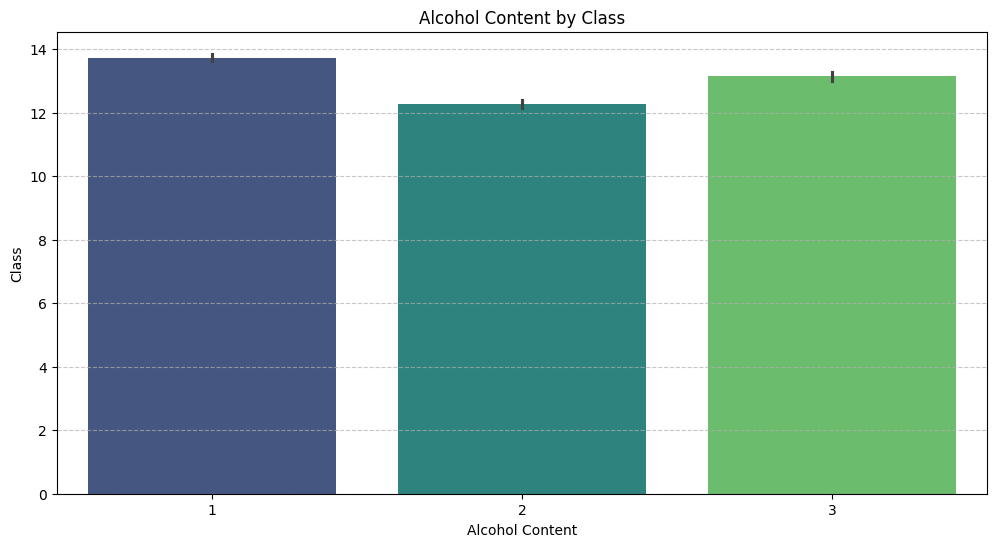

In [36]:
#Visualize the relationship between 'Alcohol' and 'Class'
plt.figure(figsize=(12, 6))
sns.barplot(x='Alcohol', y='Class', data=Wine_df, palette='viridis')
plt.title('Alcohol Content by Class')
plt.xlabel('Alcohol Content')
plt.ylabel('Class')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [27]:
train_data = pd.concat([x_train, y_train], axis=1)
test_data = pd.concat([x_test, y_test], axis=1)

#Create an encounter-level training and testing
train_data.to_csv('train_data.csv', index=False)
test_data.to_csv('test_data.csv', index=False)

#Verify there are no duplicates in the dataset
print(train_data.duplicated().sum())
print(test_data.duplicated().sum())

0
0


# **Preprocessing using Logistic Regression and Random Forest**

In [42]:
#Import StandardScale to standardize features and SimpleImputer to manage missing values

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

#Create the pipeline for Logistic Regression and Random Forest Classifier model

logistic_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

random_forest_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])



In [47]:
#Generate Random Forest predictions
rf_predictions = random_forest_pipeline.fit(x_train, y_train_int).predict(x_test)

#Generate Logistic Regression predictions
lr_predictions = logistic_pipeline.fit(x_train, y_train_int).predict(x_test)

In [62]:
# Calculate evaluation metrics for Logistic Regression
lr_accuracy = accuracy_score(y_test_int, lr_predictions)
lr_precision = precision_score(y_test_int, lr_predictions, average='weighted', zero_division=0)
lr_recall = recall_score(y_test_int, lr_predictions, average='weighted', zero_division=0)
lr_f1 = f1_score(y_test_int, lr_predictions, average='weighted', zero_division=0)

print("\nLogistic Regression Performance")
print(f"Accuracy:  {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-score:  {lr_f1:.4f}")

print("\nClassification Report for Logistic Regression:")
print(classification_report(y_test_int, lr_predictions, zero_division=0))

print("Confusion Matrix for Logistic Regression:")
print(confusion_matrix(y_test_int, lr_predictions))


Logistic Regression Performance
Accuracy:  0.6222
Precision: 0.5859
Recall:    0.6222
F1-score:  0.5871

Classification Report for Logistic Regression:
              precision    recall  f1-score   support

          11       0.00      0.00      0.00         3
          12       0.50      0.82      0.62        11
          13       0.67      0.47      0.55        17
          14       0.73      0.85      0.79        13
          15       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.38      0.43      0.39        45
weighted avg       0.59      0.62      0.59        45

Confusion Matrix for Logistic Regression:
[[ 0  3  0  0  0]
 [ 0  9  2  0  0]
 [ 0  5  8  4  0]
 [ 0  1  1 11  0]
 [ 0  0  1  0  0]]


LOGISTIC REGRESSION EVALUATION
---------------------------------------------
Accuracy:  0.6222 (62.22%)
Precision: 0.5859 (58.59%)
Recall:    0.6222 (62.22%)
F1-score:  0.5871 (58.71%)

CLASSIFICATION REPORT
---------------------------------------------
              precision    recall  f1-score   support

          11       0.00      0.00      0.00         3
          12       0.50      0.82      0.62        11
          13       0.67      0.47      0.55        17
          14       0.73      0.85      0.79        13
          15       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.38      0.43      0.39        45
weighted avg       0.59      0.62      0.59        45


CONFUSION MATRIX
---------------------------------------------
[[ 0  3  0  0  0]
 [ 0  9  2  0  0]
 [ 0  5  8  4  0]
 [ 0  1  1 11  0]
 [ 0  0  1  0  0]]


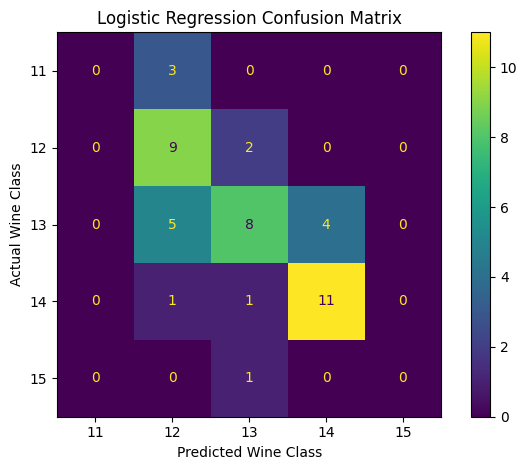

In [63]:
# Import required libraries
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt


#Create Logistic Regression pipeline

lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])



#Train Logistic Regression model

lr_model.fit(x_train, y_train_int)


#Make predictions


lr_predictions = lr_model.predict(x_test)


#Calculate evaluation metrics

lr_accuracy = accuracy_score(
    y_test_int,
    lr_predictions
)

lr_precision = precision_score(
    y_test_int,
    lr_predictions,
    average='weighted',
    zero_division=0
)

lr_recall = recall_score(
    y_test_int,
    lr_predictions,
    average='weighted',
    zero_division=0
)

lr_f1 = f1_score(
    y_test_int,
    lr_predictions,
    average='weighted',
    zero_division=0
)


#Display evaluation results

print("LOGISTIC REGRESSION EVALUATION")
print("-" * 45)

print(f"Accuracy:  {lr_accuracy:.4f} ({lr_accuracy * 100:.2f}%)")
print(f"Precision: {lr_precision:.4f} ({lr_precision * 100:.2f}%)")
print(f"Recall:    {lr_recall:.4f} ({lr_recall * 100:.2f}%)")
print(f"F1-score:  {lr_f1:.4f} ({lr_f1 * 100:.2f}%)")


#Classification Report

print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(
    classification_report(
        y_test_int,
        lr_predictions,
        zero_division=0
    )
)


#Confusion Matrix

cm = confusion_matrix(
    y_test_int,
    lr_predictions
)

print("\nCONFUSION MATRIX")
print("-" * 45)

print(cm)


#Visualize Confusion Matrix

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.unique(y_test_int)
).plot()

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Wine Class")
plt.ylabel("Actual Wine Class")
plt.tight_layout()
plt.show()

## **Logistic Regression Code Summary**

This code evaluated a Logistic Regression classification model for predicting wine classes. It first created a pipeline that applies StandardScaler to standardize the predictor variables and then trains a Logistic Regression model using the training dataset. The trained model is subsequently used to predict wine classes for the test dataset.
Model performance is evaluated using accuracy, weighted precision, weighted recall, and weighted F1-score. The weighted approach accounts for differences in the number of observations across the wine classes. A classification report provides additional class-level performance information, while the confusion matrix identified correct and incorrect predictions for each class. Finally, the confusion matrix is visualized to provide a clear graphical representation of the model classification performance. Overall, the code provides a structured process for training, testing, and evaluating the Logistic Regression model.

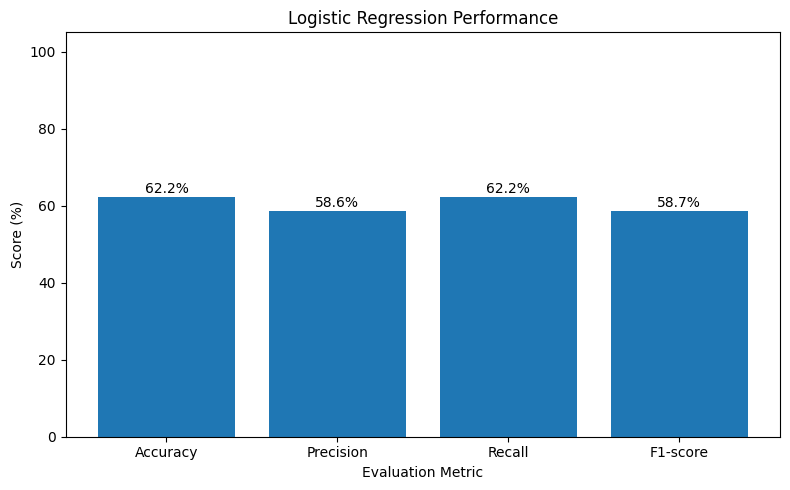

In [64]:
# Create performance summary
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score'
]

scores = [
    lr_accuracy * 100,
    lr_precision * 100,
    lr_recall * 100,
    lr_f1 * 100
]

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics,
    scores
)

plt.title("Logistic Regression Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 105)

# Add percentage values above bars
for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.1f}%",
        ha='center'
    )

plt.tight_layout()
plt.show()

### **Logistic Regression Performance Visualization Summary**

Creation of a bar also summarizes the performance of the Logistic Regression model using four key evaluation metrics: accuracy, precision, recall, and F1-score. The previously calculated metric values are converted to percentages and displayed as individual bars, making it easy to visually compare the  performance across each measure.
The chart utilized a percentage scale from 0% to 105% and places the exact percentage above each bar for easier interpretation. Accuracy represents overall classification correctness, precision reflects the reliability of the predictions. Recall measures its ability to correctly identify the wine classes, and the F1-score balances precision and recall. Overall, this visualization provides a concise and clear comparison of the Logistic Regression model classification performance.

### *** **Random Forest Evaluation**

RANDOM FOREST EVALUATION
---------------------------------------------
Accuracy:  0.5778 (57.78%)
Precision: 0.5380 (53.80%)
Recall:    0.5778 (57.78%)
F1-score:  0.5379 (53.79%)

CLASSIFICATION REPORT
---------------------------------------------
              precision    recall  f1-score   support

          11       0.00      0.00      0.00         3
          12       0.53      0.73      0.62        11
          13       0.64      0.41      0.50        17
          14       0.58      0.85      0.69        13
          15       0.00      0.00      0.00         1

    accuracy                           0.58        45
   macro avg       0.35      0.40      0.36        45
weighted avg       0.54      0.58      0.54        45


CONFUSION MATRIX
---------------------------------------------
[[ 0  3  0  0  0]
 [ 0  8  2  1  0]
 [ 0  4  7  6  0]
 [ 0  0  2 11  0]
 [ 0  0  0  1  0]]


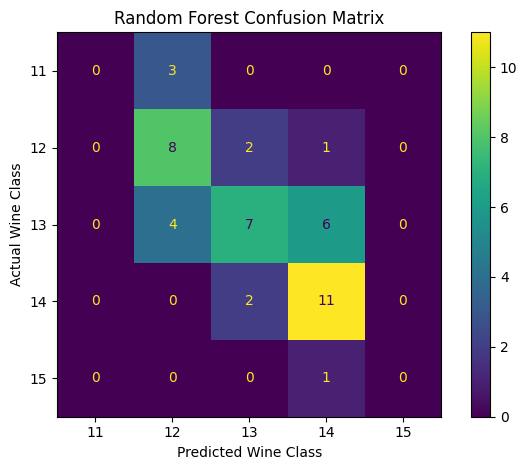

In [68]:
#Create Random Forest model

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)


#Train Random Forest model

rf_model.fit(x_train, y_train_int)


#Make predictions

rf_predictions = rf_model.predict(x_test)


#Calculate evaluation metrics

rf_accuracy = accuracy_score(
    y_test_int,
    rf_predictions
)

rf_precision = precision_score(
    y_test_int,
    rf_predictions,
    average='weighted',
    zero_division=0
)

rf_recall = recall_score(
    y_test_int,
    rf_predictions,
    average='weighted',
    zero_division=0
)

rf_f1 = f1_score(
    y_test_int,
    rf_predictions,
    average='weighted',
    zero_division=0
)


#Display evaluation results

print("RANDOM FOREST EVALUATION")
print("-" * 45)

print(f"Accuracy:  {rf_accuracy:.4f} ({rf_accuracy * 100:.2f}%)")
print(f"Precision: {rf_precision:.4f} ({rf_precision * 100:.2f}%)")
print(f"Recall:    {rf_recall:.4f} ({rf_recall * 100:.2f}%)")
print(f"F1-score:  {rf_f1:.4f} ({rf_f1 * 100:.2f}%)")


#Classification Report

print("\nCLASSIFICATION REPORT")
print("-" * 45)

print(
    classification_report(
        y_test_int,
        rf_predictions,
        zero_division=0
    )
)


#Confusion Matrix

rf_cm = confusion_matrix(
    y_test_int,
    rf_predictions
)

print("\nCONFUSION MATRIX")
print("-" * 45)

print(rf_cm)


#Visualize Confusion Matrix

ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=np.unique(y_test_int)
).plot()

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Wine Class")
plt.ylabel("Actual Wine Class")
plt.tight_layout()
plt.show()

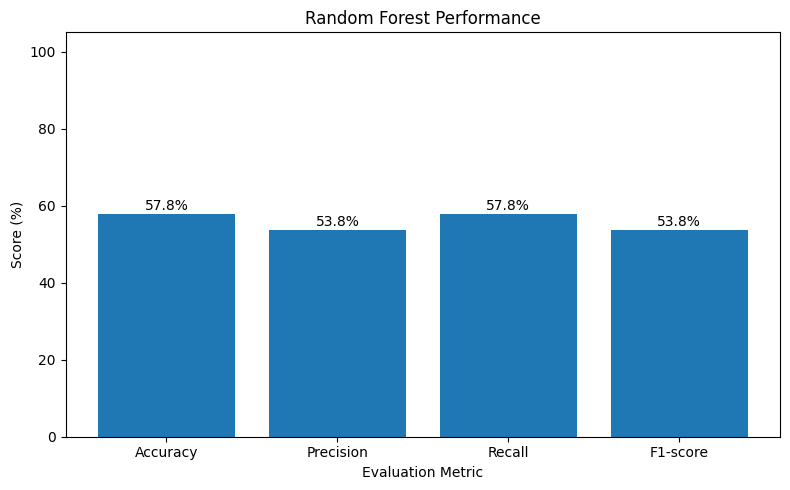

In [67]:
# Create Random Forest performance summary
rf_metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-score'
]

rf_scores = [
    rf_accuracy * 100,
    rf_precision * 100,
    rf_recall * 100,
    rf_f1 * 100
]


# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    rf_metrics,
    rf_scores
)

plt.title("Random Forest Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 105)


# Add percentage values above bars
for bar, score in zip(bars, rf_scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{score:.1f}%",
        ha='center'
    )

plt.tight_layout()
plt.show()

### **Random Forest Evaluation Summary**

The Random Forest model classified wine samples based on their measured characteristics. The model used an ensemble of 100 decision trees to generate predictions, with random_state=42 applied to ensure reproducible results. Unlike Logistic Regression, Random Forest does not require feature scaling because its tree-based structure is not affected by differences in the numerical scales of the predictor variables.
The model is evaluated using accuracy, weighted precision, weighted recall, and weighted F1-score. Accuracy measures overall classification correctness, precision evaluated the reliability of the predicted wine classes, recall measures the ability to correctly identify observations within each class, and the F1-score also provided a balance between precision and recall. The classification report provided detailed results for each wine class, while the confusion matrix identified correct predictions and misclassifications. Finally, the performance bar chart visually compares the four evaluation metrics, providing a concise assessment of the Random Forest model overall classification performance.

### **Metric Performance Evaluation**

MODEL PERFORMANCE COMPARISON
------------------------------------------------------------
   Metric  Logistic Regression  Random Forest
 Accuracy               0.6222         0.5778
Precision               0.5859         0.5380
   Recall               0.6222         0.5778
 F1-score               0.5871         0.5379

MODEL PERFORMANCE (%)
------------------------------------------------------------
   Metric  Logistic Regression  Random Forest
 Accuracy                62.22          57.78
Precision                58.59          53.80
   Recall                62.22          57.78
 F1-score                58.71          53.79


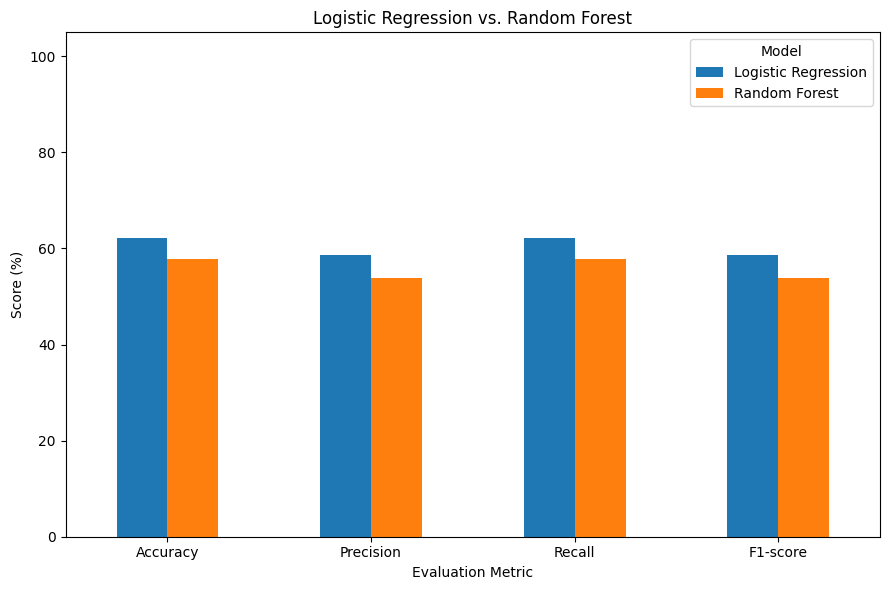


LOGISTIC REGRESSION CONFUSION MATRIX
[[ 0  3  0  0  0]
 [ 0  9  2  0  0]
 [ 0  5  8  4  0]
 [ 0  1  1 11  0]
 [ 0  0  1  0  0]]

RANDOM FOREST CONFUSION MATRIX
[[ 0  3  0  0  0]
 [ 0  8  2  1  0]
 [ 0  4  7  6  0]
 [ 0  0  2 11  0]
 [ 0  0  0  1  0]]

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

          11       0.00      0.00      0.00         3
          12       0.50      0.82      0.62        11
          13       0.67      0.47      0.55        17
          14       0.73      0.85      0.79        13
          15       0.00      0.00      0.00         1

    accuracy                           0.62        45
   macro avg       0.38      0.43      0.39        45
weighted avg       0.59      0.62      0.59        45


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

          11       0.00      0.00      0.00         3
          12       0.53      0.73      0.62        11
          13    

In [71]:
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.pyplot as plt

#Evaluate Logistic Regression

lr_accuracy = accuracy_score(y_test_int, lr_predictions)
lr_precision = precision_score(
    y_test_int, lr_predictions,
    average='weighted',
    zero_division=0
)
lr_recall = recall_score(
    y_test_int, lr_predictions,
    average='weighted',
    zero_division=0
)
lr_f1 = f1_score(
    y_test_int, lr_predictions,
    average='weighted',
    zero_division=0
)

#Evaluate Random Forest

rf_accuracy = accuracy_score(y_test_int, rf_predictions)
rf_precision = precision_score(
    y_test_int, rf_predictions,
    average='weighted',
    zero_division=0
)
rf_recall = recall_score(
    y_test_int, rf_predictions,
    average='weighted',
    zero_division=0
)
rf_f1 = f1_score(
    y_test_int, rf_predictions,
    average='weighted',
    zero_division=0
)

#Create comparison table

comparison = pd.DataFrame({
    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score'
    ],

    'Logistic Regression': [
        lr_accuracy,
        lr_precision,
        lr_recall,
        lr_f1
    ],

    'Random Forest': [
        rf_accuracy,
        rf_precision,
        rf_recall,
        rf_f1
    ]
})

print("MODEL PERFORMANCE COMPARISON")
print("-" * 60)
print(comparison.round(4).to_string(index=False))

#Display percentages

comparison_percent = comparison.copy()

comparison_percent['Logistic Regression'] *= 100
comparison_percent['Random Forest'] *= 100

print("\nMODEL PERFORMANCE (%)")
print("-" * 60)
print(comparison_percent.round(2).to_string(index=False))

#Compare models visually

comparison_percent.set_index('Metric').plot(
    kind='bar',
    figsize=(9, 6)
)

plt.title("Logistic Regression vs. Random Forest")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score (%)")
plt.ylim(0, 105)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

#Confusion matrices

print("\nLOGISTIC REGRESSION CONFUSION MATRIX")
print(confusion_matrix(y_test_int, lr_predictions))

print("\nRANDOM FOREST CONFUSION MATRIX")
print(confusion_matrix(y_test_int, rf_predictions))

#Classification reports

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_int,
        lr_predictions,
        zero_division=0
    )
)

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(
    classification_report(
        y_test_int,
        rf_predictions,
        zero_division=0
    )
)

## **Performance Evaluation Summary**

The classification models are evaluated using accuracy, precision, recall, and F1-score. Accuracy measured the overall percentage of wine samples classified correctly. Precision measured the reliability of the predicted classes, while recall measured the model's ability to correctly identify samples belonging to each class. The F1-score combined precision and recall into a single measure. Because the Wine dataset contains three classes with different numbers of observations, weighted precision, recall, and F1-score are appropriate for the overall comparison.
The confusion matrices should also be examined because they show exactly which wine classes each model predicts correctly and where misclassifications occur. A model with high overall accuracy could still perform less effectively for one particular class, which would be visible in the classification report and confusion matrix.

## **Cross Validation and Hyperparameter Tuning using GridSearchCV**

In [73]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Configure five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Create model pipelines
lr_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

rf_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestClassifier(
        random_state=42
    ))
])

In [76]:
# Logistic Regression cross-validation
lr_cv_scores = cross_val_score(
    lr_pipeline,
    x_train,
    y_train_int,
    cv=cv,
    scoring='accuracy'
)

# Random Forest cross-validation
rf_cv_scores = cross_val_score(
    rf_pipeline,
    x_train,
    y_train_int,
    cv=cv,
    scoring='accuracy'
)

print("LOGISTIC REGRESSION CROSS-VALIDATION")
print("Fold scores:", lr_cv_scores)
print(f"Mean accuracy: {lr_cv_scores.mean():.4f}")
print(f"Standard deviation: {lr_cv_scores.std():.4f}")

print("\nRANDOM FOREST CROSS-VALIDATION")
print("Fold scores:", rf_cv_scores)
print(f"Mean accuracy: {rf_cv_scores.mean():.4f}")
print(f"Standard deviation: {rf_cv_scores.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


LOGISTIC REGRESSION CROSS-VALIDATION
Fold scores: [0.44444444 0.51851852 0.61538462 0.57692308 0.69230769]
Mean accuracy: 0.5695
Standard deviation: 0.0842

RANDOM FOREST CROSS-VALIDATION
Fold scores: [0.51851852 0.48148148 0.61538462 0.57692308 0.65384615]
Mean accuracy: 0.5692
Standard deviation: 0.0626
